# 03 · Fine-tuned multilingual encoder
`python src/train_encoder.py --model microsoft/mdeberta-v3-base --name mdeberta --epochs 2 --bs 4 --accum 4`

* Backbone: mDeBERTa-v3-base (multilingual, 100+ languages incl. German), 3-way classification head.
* Data: the same fixed 50k training subsample and the same validation fold as the baseline.
* Optimisation: AdamW, lr 2e-5, linear warm-up 6% + decay, effective batch 16, 2 epochs, bf16 autocast. The 250k-token embedding matrix is frozen (it is 2/3 of the weights; freezing saves ~3 GB so the model trains on an 8 GB GPU).
* **Long texts.** 68% of texts are longer than 510 tokens and half of all tokens lie beyond the first window. Training: each epoch draws a random 510-token window from every text (a cheap augmentation that exposes the model to all parts of a document). Inference: overlapping windows (510 tokens, stride 384, at most 8 windows incl. the tail); per-window logits are cached so aggregations can be compared offline.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parent / 'src'))
from common import ROOT, PRED, RES, LABELS, fixed_sets, y_of
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
IMG = Path(ROOT) / 'images'
plt.rcParams.update({'figure.dpi': 110})
sub, val, test = fixed_sets(); yv = y_of(val)

def chunk_probs(name, split='val'):
    z = np.load(Path(PRED) / f'{name}_chunks_{split}.npz'); lg, doc = z['logits'], z['doc']
    p = np.exp(lg - lg.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
    return p, doc

def aggregations(name, n):
    p, doc = chunk_probs(name)
    df = pd.DataFrame(p, columns=LABELS); df['doc'] = doc
    g = df.groupby('doc')[LABELS]
    first, last, mean = g.first().values, g.last().values, g.mean().values
    lmean = np.exp(np.log(df[LABELS].clip(1e-6)).groupby(df.doc).mean().values)
    return {'first window (truncation)': first, 'head + tail': (first + last) / 2,
            'mean over windows': mean, 'geometric mean': lmean}

def f1row(p):
    f = f1_score(yv, p.argmax(1), average=None)
    return {'macro_f1': f.mean(), **{f'f1_{l}': v for l, v in zip(LABELS, f)}}

## 1. Long-text handling at inference

In [2]:
rows = []
for name in ['mdeberta', 'xlmr', 'xlmr_head', 'mdeberta_150k', 'xlmr_150k', 'xlmr_full']:
    if not (Path(PRED) / f'{name}_chunks_val.npz').exists(): continue
    for agg, p in aggregations(name, len(val)).items():
        rows.append({'model': name, 'aggregation': agg, **f1row(p)})
agg_tab = pd.DataFrame(rows).round(4); agg_tab

,model,aggregation,macro_f1,f1_human,f1_ai,f1_fusion
0,mdeberta,first window (truncation),0.8564,0.7902,0.9836,0.7953
1,mdeberta,head + tail,0.9034,0.8545,0.9829,0.8727
2,mdeberta,mean over windows,0.9103,0.8567,0.9897,0.8844
3,mdeberta,geometric mean,0.9157,0.8626,0.9908,0.8936
4,xlmr,first window (truncation),0.8649,0.7951,0.9845,0.8151
5,xlmr,head + tail,0.9063,0.8557,0.9841,0.8791
6,xlmr,mean over windows,0.9062,0.8505,0.9880,0.8801
7,xlmr,geometric mean,0.9140,0.8599,0.9893,0.8929
8,xlmr_head,first window (truncation),0.8693,0.7974,0.9900,0.8206
9,xlmr_head,head + tail,0.8939,0.8235,0.9892,0.8688


## 2. Encoder vs baseline on the same split

,model,macro_f1,f1_human,f1_ai,f1_fusion
0,TF-IDF word 1-3 + LR (50k),0.8841,0.8330,0.9852,0.8342
1,"mDeBERTa-v3-base (50k, mean over windows)",0.9103,0.8567,0.9897,0.8844


              precision    recall  f1-score   support

       human     0.8851    0.8302    0.8567      6671
          ai     0.9832    0.9962    0.9897     12192
      fusion     0.8714    0.8977    0.8844      8367

    accuracy                         0.9253     27230
   macro avg     0.9132    0.9080    0.9103     27230
weighted avg     0.9248    0.9253    0.9247     27230



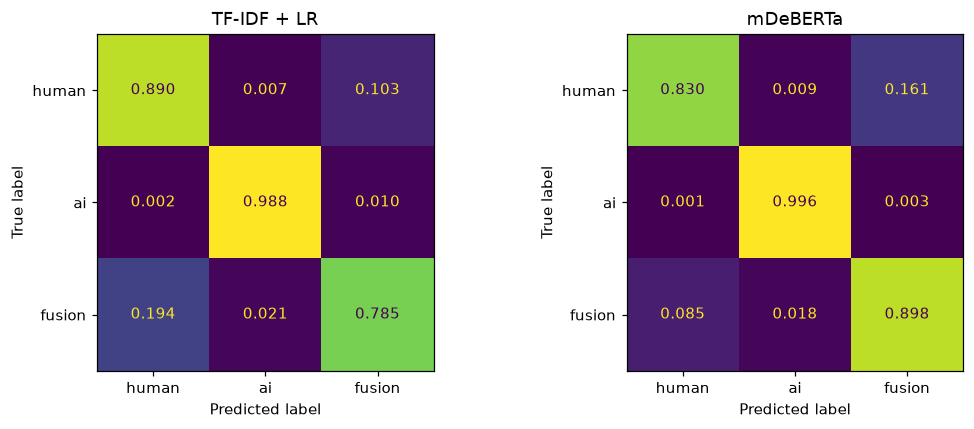

In [3]:
pb = np.load(Path(PRED) / 'baseline_val.npy')
pe = aggregations('mdeberta', len(val))['mean over windows']
cmp = pd.DataFrame([{'model': 'TF-IDF word 1-3 + LR (50k)', **f1row(pb)},
                    {'model': 'mDeBERTa-v3-base (50k, mean over windows)', **f1row(pe)}]).round(4)
display(cmp)
print(classification_report(yv, pe.argmax(1), target_names=LABELS, digits=4))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, p, t in [(ax[0], pb, 'TF-IDF + LR'), (ax[1], pe, 'mDeBERTa')]:
    ConfusionMatrixDisplay(confusion_matrix(yv, p.argmax(1), normalize='true'), display_labels=LABELS).plot(ax=a, colorbar=False, values_format='.3f'); a.set_title(t)
plt.tight_layout(); plt.savefig(IMG / 'encoder_vs_baseline_cm.png', bbox_inches='tight'); plt.show()

In [4]:
val['enc'] = pe.argmax(1); val['tfidf'] = pb.argmax(1)
dom = val.groupby('domain').apply(lambda d: pd.Series({'n': len(d),
        'tfidf': f1_score(y_of(d), d.tfidf, average='macro'), 'mdeberta': f1_score(y_of(d), d.enc, average='macro')}), include_groups=False)
dom.round(3)

,n,tfidf,mdeberta
domain,,,
arxiv_papers,1428.0,0.915,0.622
blog_authorship_corpus,4053.0,0.767,0.861
bundestag,5232.0,0.925,0.899
cnn_news,4427.0,0.872,0.973
euro_court_cases,2757.0,0.909,0.859
gutenberg,734.0,0.781,0.778
house_of_commons,3187.0,0.906,0.917
student_essays,5412.0,0.904,0.929


## 3. Errors: does the encoder agree with the baseline?

In [5]:
both = pd.crosstab(val.enc == yv, val.tfidf == yv, rownames=['encoder correct'], colnames=['tfidf correct'])
display(both)
print('oracle (either correct):', round(((val.enc == yv) | (val.tfidf == yv)).mean(), 4))

tfidf correct,False,True
encoder correct,,
False,796,1239
True,1881,23314


oracle (either correct): 0.9708
